# Chapitre 8 - Lab : validation à deux phases avec PostgreSQL

PostgreSQL expose les deux phases de 2PC aux applications : `PREPARE TRANSACTION 'id'`
(phase 1 : le participant écrit tout sur disque et promet de pouvoir valider) puis
`COMMIT PREPARED 'id'` ou `ROLLBACK PREPARED 'id'` (phase 2). C'est la brique qu'utilisent
les gestionnaires de transactions XA. Ce lab écrit un **coordinateur** minimal en Python
entre deux bases (deux banques), puis observe sur le vrai système ce que le cours 5 a
simulé : transactions en doute, verrous tenus, survie à un redémarrage, reprise par le
journal du coordinateur, décision heuristique, et coût en latence.

**Démarrer et arrêter PostgreSQL** (depuis la racine du dépôt ; `max_prepared_transactions`
est activé dans le `compose.yml`) :

```bash
docker compose -f docker/transactions/compose.yml -p ddia_transactions up -d
# ... exécuter le notebook ...
docker compose -f docker/transactions/compose.yml -p ddia_transactions down -v
```

**Plan.**

1. Deux participants et un coordinateur journalisé.
2. Une validation à deux phases réussie, pas à pas.
3. Le coordinateur tombe après la préparation : transactions en doute et verrous tenus.
4. Une transaction préparée survit au redémarrage de la base.
5. Reprise par le journal du coordinateur.
6. La décision heuristique : quand l'administrateur se trompe.
7. Le coût de 2PC en latence.

In [1]:
import json
import os
import subprocess
import tempfile
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import psycopg
from psycopg import errors

from ddia.timelines import SpaceTime
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET,
                           annotate_bars, finish, set_style, subtitle)

set_style()
plt.rcParams["axes.titlepad"] = 16
BASE = "host=localhost port=10832 user=ddia password=ddia connect_timeout=5"
CONTENEUR = "ddia_transactions-postgres-1"
BANQUES = ["banque_a", "banque_b"]


def attendre_postgres(timeout=60):
    t0 = time.time()
    while time.time() - t0 < timeout:
        try:
            with psycopg.connect(BASE + " dbname=ddia", autocommit=True) as c:
                c.execute("SELECT 1")
                return time.time() - t0
        except psycopg.OperationalError:
            time.sleep(0.5)
    raise RuntimeError("PostgreSQL ne répond pas : lancer docker compose (voir ci-dessus)")


print(f"PostgreSQL prêt ({attendre_postgres():.1f} s)")
with psycopg.connect(BASE + " dbname=ddia", autocommit=True) as c:
    print("max_prepared_transactions =", c.execute("SHOW max_prepared_transactions").fetchone()[0])
    # nettoyage d'une exécution précédente : des transactions préparées empêchent DROP DATABASE
    for gid, base_ in c.execute("SELECT gid, database FROM pg_prepared_xacts").fetchall():
        with psycopg.connect(BASE + f" dbname={base_}", autocommit=True) as c2:
            c2.execute(f"ROLLBACK PREPARED '{gid}'")
    for b in BANQUES:
        c.execute(f"DROP DATABASE IF EXISTS {b} WITH (FORCE)")
        c.execute(f"CREATE DATABASE {b}")


def connexion(banque, autocommit=False):
    return psycopg.connect(BASE + f" dbname={banque}", autocommit=autocommit)


def sql(banque, requete, params=None):
    with connexion(banque, autocommit=True) as c:
        cur = c.execute(requete, params)
        return cur.fetchall() if cur.description else None


def init_comptes():
    for b in BANQUES:
        for gid, in sql(b, "SELECT gid FROM pg_prepared_xacts WHERE database = current_database()"):
            sql(b, f"ROLLBACK PREPARED '{gid}'")
        sql(b, "DROP TABLE IF EXISTS comptes; CREATE TABLE comptes (id text PRIMARY KEY, solde int NOT NULL CHECK (solde >= 0));"
               "INSERT INTO comptes VALUES ('inès', 1000)")


def soldes():
    return {b: sql(b, "SELECT solde FROM comptes WHERE id = 'inès'")[0][0] for b in BANQUES}


def preparees():
    lignes = []
    for b in BANQUES:
        for gid, prepared in sql(b, "SELECT gid, prepared FROM pg_prepared_xacts WHERE database = current_database()"):
            lignes.append(dict(base=b, gid=gid, préparée_à=prepared.strftime("%H:%M:%S")))
    return pd.DataFrame(lignes, columns=["base", "gid", "préparée_à"])

PostgreSQL prêt (0.0 s)
max_prepared_transactions = 10


## 1. Deux participants et un coordinateur journalisé (section *Two-Phase Commit*)

Chaque banque est une base distincte (un participant). Inès a 1 000 € dans chacune. Un
virement de 100 € de la banque A vers la banque B doit être atomique : débit **et** crédit,
ou ni l'un ni l'autre.

Les identifiants de transaction préparée (`gid`) sont uniques pour tout le serveur ; nos
deux « banques » partageant le même serveur, chaque participant reçoit l'identifiant
global suffixé de son nom (`vir-3:banque_a`).

Le coordinateur est une petite classe Python :

- il ouvre une transaction locale sur chaque participant et y fait les écritures ;
- phase 1 : `PREPARE TRANSACTION 'gid'` sur chacun (si l'un échoue, il annule tout) ;
- il écrit sa **décision** dans un journal sur disque (un fichier JSON, `fsync`) : c'est le
  point de validation ;
- phase 2 : `COMMIT PREPARED 'gid'` (ou `ROLLBACK PREPARED`) sur chacun.

L'option `panne_apres` permet de « tuer » le coordinateur à un point donné.

In [2]:
class Panne(Exception):
    pass


class Coordinateur:
    def __init__(self, journal):
        self.journal = journal

    def journaliser(self, gid, decision):
        with open(self.journal, "a") as f:
            f.write(json.dumps({"gid": gid, "décision": decision}) + "\n")
            f.flush()
            os.fsync(f.fileno())

    def decisions(self):
        if not os.path.exists(self.journal):
            return {}
        with open(self.journal) as f:
            return {d["gid"]: d["décision"] for d in map(json.loads, f)}

    def virement(self, gid, montant, panne_apres=None):
        conns = {b: connexion(b) for b in BANQUES}
        prepares = []
        try:
            try:                                              # exécution puis phase 1
                conns["banque_a"].execute("UPDATE comptes SET solde = solde - %s WHERE id = 'inès'", (montant,))
                conns["banque_b"].execute("UPDATE comptes SET solde = solde + %s WHERE id = 'inès'", (montant,))
                for b, c in conns.items():
                    c.execute(f"PREPARE TRANSACTION '{gid}:{b}'")
                    prepares.append(b)
            except psycopg.Error as e:                        # un participant refuse : abandon partout
                for b, c in conns.items():
                    c.rollback()
                for b in prepares:
                    sql(b, f"ROLLBACK PREPARED '{gid}:{b}'")
                self.journaliser(gid, "abort")
                return f"annulé ({type(e).__name__})"
            if panne_apres == "prepare":
                raise Panne
            self.journaliser(gid, "commit")                   # point de validation
            for b in BANQUES:                                 # phase 2
                if panne_apres == f"commit_{b}":
                    raise Panne
                sql(b, f"COMMIT PREPARED '{gid}:{b}'")
            return "validé"
        except Panne:
            return "PANNE DU COORDINATEUR"
        finally:
            for c in conns.values():
                c.close()


journal = os.path.join(tempfile.mkdtemp(), "coordinateur.jsonl")
coord = Coordinateur(journal)
init_comptes()
soldes()

{'banque_a': 1000, 'banque_b': 1000}

## 2. Une validation à deux phases réussie, pas à pas (section *A system of promises*)

Déroulons un virement à la main pour observer l'état intermédiaire : après les deux
`PREPARE TRANSACTION`, les transactions n'appartiennent plus à aucune session ; elles
sont listées dans la vue système `pg_prepared_xacts`, et leurs écritures ne sont pas
encore visibles.

In [3]:
ca, cb = connexion("banque_a"), connexion("banque_b")
ca.execute("UPDATE comptes SET solde = solde - 100 WHERE id = 'inès'")
cb.execute("UPDATE comptes SET solde = solde + 100 WHERE id = 'inès'")
ca.execute("PREPARE TRANSACTION 'vir-1:banque_a'")
cb.execute("PREPARE TRANSACTION 'vir-1:banque_b'")
ca.close(); cb.close()                     # les sessions peuvent disparaître : la promesse reste
print("après la phase 1, soldes visibles :", soldes())
display(preparees())
sql("banque_a", "COMMIT PREPARED 'vir-1:banque_a'")
sql("banque_b", "COMMIT PREPARED 'vir-1:banque_b'")
print("après la phase 2 :", soldes(), "; transactions préparées restantes :", len(preparees()))

après la phase 1, soldes visibles : {'banque_a': 1000, 'banque_b': 1000}


,base,gid,préparée_à
0,banque_a,vir-1:banque_a,10:52:39
1,banque_b,vir-1:banque_b,10:52:39


après la phase 2 : {'banque_a': 900, 'banque_b': 1100} ; transactions préparées restantes : 0


Après la phase 1, les soldes visibles sont inchangés (1 000 / 1 000) et deux transactions
préparées attendent ; on a même fermé les connexions qui les avaient créées : un
participant qui a voté oui garde sa promesse indépendamment de la session. Après la
phase 2, le virement est appliqué (900 / 1 100).

Un participant qui ne peut pas tenir sa promesse doit **refuser de préparer**. Ici, la
contrainte `CHECK (solde >= 0)` fait échouer un virement trop gros dès l'`UPDATE` : le
coordinateur annule partout.

In [4]:
print("virement de 5 000 € :", coord.virement("vir-2", 5000))
print("soldes :", soldes(), "; préparées :", len(preparees()))

virement de 5 000 € : annulé (CheckViolation)
soldes : {'banque_a': 900, 'banque_b': 1100} ; préparées : 0


> **À retenir.** `PREPARE TRANSACTION` est le vote oui : tout est écrit sur disque, la
> transaction ne peut plus échouer pour une raison locale, mais rien n'est encore visible.

## 3. Le coordinateur tombe après la préparation (sections *Coordinator failure* et *Holding locks while in doubt*)

Faisons tomber le coordinateur juste après la phase 1, **avant** d'avoir journalisé sa
décision. Les deux participants restent en doute. Une autre application veut alors
modifier le compte d'Inès dans la banque A : elle est bloquée par le verrou de la
transaction préparée (on limite l'attente avec `lock_timeout`).

In [5]:
print("virement vir-3 :", coord.virement("vir-3", 100, panne_apres="prepare"))
display(preparees())
# les verrous d'une transaction préparée n'appartiennent à aucun processus (pid vide)
verrous = sql("banque_a", "SELECT locktype, coalesce(relation::regclass::text, transactionid::text), mode, granted "
                          "FROM pg_locks WHERE pid IS NULL ORDER BY locktype")
display(pd.DataFrame(verrous, columns=["type", "objet", "mode", "accordé"]))
attentes = []
for essai in range(3):
    with connexion("banque_a") as c:
        c.execute("SET lock_timeout = '1s'")
        t0 = time.perf_counter()
        try:
            c.execute("UPDATE comptes SET solde = solde + 1 WHERE id = 'inès'")
            res = "réussi"
        except errors.LockNotAvailable:
            res = "bloqué (lock_timeout)"
        attentes.append(dict(essai=essai + 1, résultat=res, attente_s=round(time.perf_counter() - t0, 2)))
        c.rollback()
pd.DataFrame(attentes)

virement vir-3 : PANNE DU COORDINATEUR


,base,gid,préparée_à
0,banque_a,vir-3:banque_a,10:52:39
1,banque_b,vir-3:banque_b,10:52:39


,type,objet,mode,accordé
0,relation,17076,RowExclusiveLock,True
1,relation,17070,RowExclusiveLock,True
2,relation,comptes_pkey,RowExclusiveLock,True
3,relation,comptes,RowExclusiveLock,True
4,transactionid,15811,ExclusiveLock,True
5,transactionid,15810,ExclusiveLock,True


,essai,résultat,attente_s
0,1,bloqué (lock_timeout),1.0
1,2,bloqué (lock_timeout),1.0
2,3,bloqué (lock_timeout),1.0


Les deux transactions préparées détiennent des verrous (dont un `RowExclusiveLock` sur la
table et le verrou sur l'identifiant de transaction que les autres attendent) ; aucune
session n'existe pour les libérer. Chaque tentative de modification du compte attend la
seconde de `lock_timeout` puis échoue : sans le coordinateur, la ligne est **indisponible**.

> **À retenir.** Une transaction préparée garde ses verrous tant que la décision n'est
> pas arrivée : la panne du coordinateur devient une panne de disponibilité des données.

## 4. Une transaction préparée survit au redémarrage de la base (section *Recovering from coordinator failure*)

Le livre précise qu'une implémentation correcte de 2PC doit conserver les transactions
préparées, et leurs verrous, même à travers un redémarrage. Redémarrons le conteneur
PostgreSQL.

In [6]:
t0 = time.perf_counter()
subprocess.run(["docker", "restart", CONTENEUR], check=True, capture_output=True)
print(f"redémarrage : {time.perf_counter() - t0:.1f} s, puis base disponible en {attendre_postgres():.1f} s")
display(preparees())
with connexion("banque_a") as c:
    c.execute("SET lock_timeout = '1s'")
    try:
        c.execute("UPDATE comptes SET solde = solde + 1 WHERE id = 'inès'")
        print("modification du compte : réussie")
    except errors.LockNotAvailable:
        print("modification du compte : toujours bloquée après le redémarrage")
    c.rollback()

redémarrage : 0.3 s, puis base disponible en 0.5 s


,base,gid,préparée_à
0,banque_a,vir-3:banque_a,10:52:39
1,banque_b,vir-3:banque_b,10:52:39


modification du compte : toujours bloquée après le redémarrage


Les deux transactions préparées sont toujours là (PostgreSQL les a reconstruites à partir
de son journal) et le compte reste verrouillé : redémarrer la base ne « débloque » rien,
et c'est voulu, sinon l'atomicité serait compromise.

> **À retenir.** La promesse d'un participant est **durable** : elle survit aux pannes et
> aux redémarrages, avec ses verrous.

## 5. Reprise par le journal du coordinateur

Le coordinateur redémarre et relit son journal. Pour chaque transaction préparée trouvée
chez les participants : si le journal contient `commit`, il la valide partout ; sinon, il
l'annule (**abandon présumé** : aucune décision n'a pu être communiquée).

Première reprise : `vir-3`, préparé dans les deux banques, n'a aucune décision dans le
journal.

In [7]:
def reprise(coord):
    decisions = coord.decisions()
    actions = []
    for _, ligne in preparees().iterrows():
        global_id = ligne["gid"].split(":")[0]
        d = decisions.get(global_id, "abort")
        sql(ligne["base"], f"{'COMMIT' if d == 'commit' else 'ROLLBACK'} PREPARED '{ligne['gid']}'")
        actions.append(dict(base=ligne["base"], gid=ligne["gid"], journal=decisions.get(global_id, "(absent)"),
                            action=f"{'COMMIT' if d == 'commit' else 'ROLLBACK'} PREPARED"))
    return pd.DataFrame(actions)


display(reprise(coord))
print("après reprise :", soldes(), "; total =", sum(soldes().values()))

,base,gid,journal,action
0,banque_a,vir-3:banque_a,(absent),ROLLBACK PREPARED
1,banque_b,vir-3:banque_b,(absent),ROLLBACK PREPARED


après reprise : {'banque_a': 900, 'banque_b': 1100} ; total = 2000


`vir-3` est annulé dans les deux banques (abandon présumé). Provoquons maintenant une
panne **après** la journalisation de `commit`, quand seule la banque A a reçu `COMMIT
PREPARED`, puis une seconde reprise.

In [8]:
print("virement vir-4 :", coord.virement("vir-4", 100, panne_apres="commit_banque_b"))
print("soldes visibles :", soldes(), "(la banque A a débité, la banque B pas encore crédité)")
display(preparees())
display(reprise(coord))
print("après reprise :", soldes(), "; total =", sum(soldes().values()), "; préparées :", len(preparees()))

virement vir-4 : PANNE DU COORDINATEUR
soldes visibles : {'banque_a': 800, 'banque_b': 1100} (la banque A a débité, la banque B pas encore crédité)


,base,gid,préparée_à
0,banque_b,vir-4:banque_b,10:52:44


,base,gid,journal,action
0,banque_b,vir-4:banque_b,commit,COMMIT PREPARED


après reprise : {'banque_a': 800, 'banque_b': 1200} ; total = 2000 ; préparées : 0


`vir-4` a `commit` dans le journal : la reprise le valide dans la banque B (la banque A
l'avait déjà). Le total reste 2 000 € : l'atomicité est préservée, au prix d'une
indisponibilité qui a duré jusqu'à la reprise.

## 6. La décision heuristique : quand l'administrateur se trompe

Si le journal du coordinateur est perdu, un administrateur doit trancher à la main. Le
livre rappelle que la « décision heuristique » est un euphémisme pour « atomicité
probablement violée ». Rejouons-le : le coordinateur décide commit, valide la banque A,
tombe, et son disque est perdu ; l'administrateur, pressé, annule ce qu'il voit en doute
dans la banque B.

In [9]:
os.remove(journal)                                   # le disque du coordinateur est perdu
print("virement vir-5 :", coord.virement("vir-5", 100, panne_apres="commit_banque_b"))
os.remove(journal)
display(preparees())
sql("banque_b", "ROLLBACK PREPARED 'vir-5:banque_b'")          # décision « heuristique »
s_ = soldes()
print("soldes :", s_, "; total =", sum(s_.values()), "€ (100 € ont disparu)")

virement vir-5 : PANNE DU COORDINATEUR


,base,gid,préparée_à
0,banque_b,vir-5:banque_b,10:52:44


soldes : {'banque_a': 700, 'banque_b': 1200} ; total = 1900 € (100 € ont disparu)


La banque A a débité, la banque B n'a jamais crédité : 100 € ont disparu. Pour bien
décider, l'administrateur aurait dû examiner **tous** les participants (ici, constater que
la banque A avait validé `vir-5`, ce que `pg_prepared_xacts` ne montre plus, puisqu'elle
n'y figure plus) et appliquer la même issue partout. Sous la pression d'une panne, c'est
facile à rater.

> **À retenir.** Sans le journal du coordinateur, plus personne ne connaît la décision ;
> toute décision manuelle sans enquête complète risque de casser l'atomicité.

## 7. Le coût de 2PC en latence (section *Distributed Transactions Across Different Systems*)

Mesurons 200 virements de 1 € : (a) deux transactions locales indépendantes (non
atomiques entre elles, pour comparaison), (b) 2PC (`PREPARE` puis `COMMIT PREPARED` sur
chaque base, plus le `fsync` du journal du coordinateur).

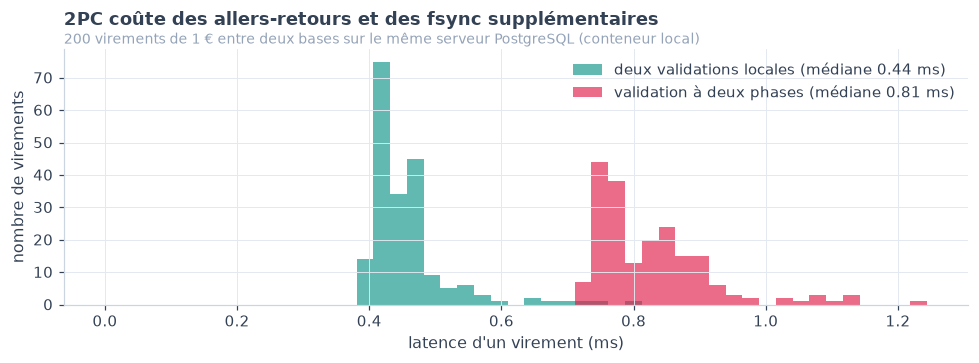

soldes finaux : {'banque_a': 600, 'banque_b': 1400}


,deux validations locales,validation à deux phases
50%,0.439177,0.808568
99%,0.741118,1.243799
mean,0.461768,0.832682


In [10]:
init_comptes()
coord = Coordinateur(os.path.join(tempfile.mkdtemp(), "coordinateur.jsonl"))
ca, cb = connexion("banque_a"), connexion("banque_b")
fa, fb = connexion("banque_a", autocommit=True), connexion("banque_b", autocommit=True)  # phase 2
lat = {"deux validations locales": [], "validation à deux phases": []}
for i in range(200):
    t0 = time.perf_counter()
    ca.execute("UPDATE comptes SET solde = solde - 1 WHERE id = 'inès'"); ca.commit()
    cb.execute("UPDATE comptes SET solde = solde + 1 WHERE id = 'inès'"); cb.commit()
    lat["deux validations locales"].append(time.perf_counter() - t0)
    t0 = time.perf_counter()
    ca.execute("UPDATE comptes SET solde = solde - 1 WHERE id = 'inès'")
    cb.execute("UPDATE comptes SET solde = solde + 1 WHERE id = 'inès'")
    ca.execute(f"PREPARE TRANSACTION 'm{i}:a'"); cb.execute(f"PREPARE TRANSACTION 'm{i}:b'")
    coord.journaliser(f"m{i}", "commit")
    fa.execute(f"COMMIT PREPARED 'm{i}:a'"); fb.execute(f"COMMIT PREPARED 'm{i}:b'")
    lat["validation à deux phases"].append(time.perf_counter() - t0)
fa.close(); fb.close()
ca.close(); cb.close()
lat = pd.DataFrame(lat) * 1e3
fig, ax = plt.subplots(figsize=(9, 3.4))
bins = np.linspace(0, lat.quantile(0.99).max(), 50)
for (nom, v), c in zip(lat.items(), [TEAL, ROSE]):
    ax.hist(v, bins=bins, alpha=0.65, color=c, label=f"{nom} (médiane {v.median():.2f} ms)")
ax.set_xlabel("latence d'un virement (ms)")
ax.set_ylabel("nombre de virements")
ax.set_title("2PC coûte des allers-retours et des fsync supplémentaires")
subtitle(ax, "200 virements de 1 € entre deux bases sur le même serveur PostgreSQL (conteneur local)")
ax.legend()
plt.tight_layout(); plt.show()
print("soldes finaux :", soldes())
lat.describe(percentiles=[0.5, 0.99]).loc[["50%", "99%", "mean"]]

Même en local (aucune latence réseau réelle), le virement par 2PC coûte nettement plus
cher que deux validations indépendantes : deux instructions de plus par participant, une
écriture durable supplémentaire par participant (l'état préparé) et le `fsync` du journal
du coordinateur. Avec un vrai réseau entre machines, il faut ajouter un aller-retour par
phase.

> **À retenir.** 2PC garantit l'atomicité entre bases au prix d'une latence accrue et,
> surtout, d'une dépendance forte envers la disponibilité du coordinateur.

## Synthèse

- `PREPARE TRANSACTION` / `COMMIT PREPARED` / `ROLLBACK PREPARED` sont les deux phases de
  2PC côté participant ; `pg_prepared_xacts` liste les transactions en doute.
- Une transaction préparée garde ses verrous et survit au redémarrage de la base : sans
  coordinateur, les lignes concernées restent indisponibles.
- Le journal du coordinateur est la seule source de vérité sur la décision ; s'il est
  perdu, la décision manuelle risque de casser l'atomicité.

Pensez à arrêter le conteneur :

```bash
docker compose -f docker/transactions/compose.yml -p ddia_transactions down -v
```